In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_PATH = "../dataset/house_price_dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:\n", df.isna().sum())

numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="object").columns

for col in numeric_cols:
    if col not in ["House_ID", "Price"]:
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())


Dataset shape: (15025, 18)


,House_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated,Price
0,3975,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no,309277.0
1,12325,2646.2,2.0,5.0,2.0,2005,riverside,NaN,no,3.0,6998.6,EXCELLENT,3.67,14.55,7.45,yes,Y,563512.0
2,7202,2791.2,4.0,3.0,3.0,2011,Lake side,Unfurnished,NO,0.0,3427.6,good,8.97,38.84,NaN,Yes,no,495806.0
3,8355,1594.1,2.0,3.0,1.0,1972,Hillview,semifurnished,no,3.0,5703.1,fair,1.54,38.31,1.60,no,Yes,240776.0
4,12742,3227.0,3.0,5.0,2.0,1995,NaN,Unfurnished,yes,3.0,7352.4,Good,5.06,30.50,4.72,no,yes,413975.0



Missing values:
 House_ID                         0
Area_sqft                      603
Bedrooms                       450
Bathrooms                      300
Floors                           0
Year_Built                       0
Location                       751
Furnishing_Status              901
Parking_Available              603
Garage_Count                   300
Lot_Size_sqft                  450
Condition                      450
Distance_to_City_Center_km     300
Crime_Rate_Index                 0
School_Rating                 1051
Has_Pool                         0
Renovated                        0
Price                            0
dtype: int64
House_ID                      0
Area_sqft                     0
Bedrooms                      0
Bathrooms                     0
Floors                        0
Year_Built                    0
Location                      0
Furnishing_Status             0
Parking_Available             0
Garage_Count                  0
Lot_Size_sqft      

In [36]:
X = df[["Area_sqft"]]
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Intercept:", model.named_steps["linearregression"].intercept_)
print("Coefficient:", model.named_steps["linearregression"].coef_[0])
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:", r2_score(y_test, y_pred))

Intercept: 81322.82609318855
Coefficient: 131.02001357987896
MAE: 59789.54548234977
RMSE: 75656.18383531006
R²: 0.6660743118279651


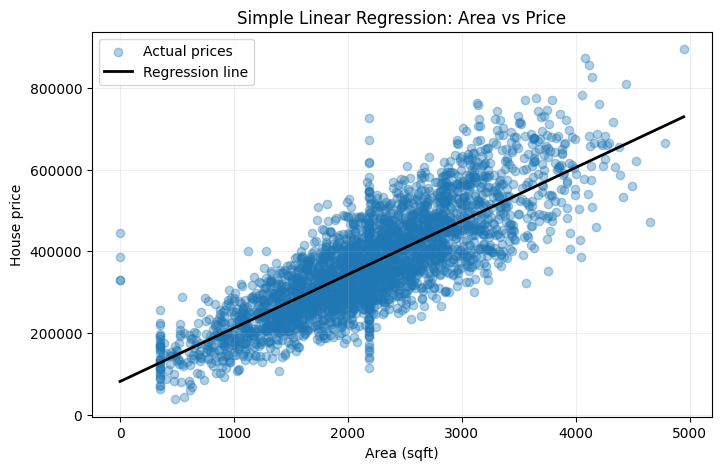

In [37]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test["Area_sqft"], y_test, alpha=0.35, label="Actual prices")
order = np.argsort(X_test["Area_sqft"].to_numpy())
plt.plot(X_test["Area_sqft"].to_numpy()[order], y_pred[order],
         linewidth=2, color='000', label="Regression line")
plt.xlabel("Area (sqft)")
plt.ylabel("House price")
plt.title("Simple Linear Regression: Area vs Price")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [39]:
sample_area = pd.DataFrame({"Area_sqft": [2000]})
print("Predicted price for a 2000 sqft house:",
      model.predict(sample_area)[0])

Predicted price for a 2000 sqft house: 343362.85325294646
